# 10 · Figuras 4, 5 y 6 del informe

Tres figuras que no necesitan modelos nuevos de Home Credit: todo sale de las predicciones que ya guardaron el 02, el 05 y el 08 (el último bloque entrena una SNGP chiquita en 2 dimensiones, que tarda un par de minutos). Los archivos quedaron con el prefijo `extra_` porque nacieron como figuras para redes, pero tres de ellas terminaron en el informe:

| En el informe | Archivo | Bloque |
|---|---|---|
| Figura 4 (rangos XGBoost contra ensamble, ρ = 0,94) | `outputs/extra_rangos_xgb_ensamble.pdf` | 3 |
| Figura 5 (densidades con el corte conformal) | `outputs/extra_densidades_conformal.pdf` | 2 |
| Figura 6 (mapa de la simulación en 2D) | `outputs/extra_mapa_simulacion.pdf` | 4 |

- **Lee:** `outputs/ids_test.csv`, `outputs/preds/xgboost_test.csv`, `sngp_vars_test.csv` y `sngp_ensamble.npz`.
- **Números del informe que salen de acá:** el ρ = 0,94 de la Figura 4, el "aprueba 55%/54%" de la Figura 5 y, en la sección 4.3, el 92% de aprobación con 9,2% de morosos y las medianas de 2,77 y 6,45 del mapa.

In [1]:
# Bloque 1. Cargamos las predicciones del pool (XGBoost, SNGP y ensamble), las alineamos por ID y fijamos el estilo
# de las figuras.
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import PercentFormatter
from scipy.stats import gaussian_kde, spearmanr, rankdata
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

from conformal import conformal_select
from redes import SNGP, entrenar, ajustar_covarianza, predecir

SEED = 42
ids_po = pd.read_csv("outputs/ids_test.csv")["SK_ID_CURR"].to_numpy()          # orden de las filas del pool
xgb = pd.read_csv("outputs/preds/xgboost_test.csv").set_index("SK_ID_CURR").loc[ids_po]
sn = pd.read_csv("outputs/preds/sngp_vars_test.csv").set_index("SK_ID_CURR").loc[ids_po]
ens = np.load("outputs/preds/sngp_ensamble.npz")                               # matrices [5, n] en el orden de ids_po

y = xgb["TARGET"].to_numpy().astype(int)                                       # 1 = moroso
thin = xgb["thin_file"].to_numpy().astype(bool)
lg = {"XGBoost": xgb["logit"].to_numpy(), "SNGP": sn["logit"].to_numpy(),
      "Ensamble": ens["lg_po"].mean(0)}                                        # logit de default de cada modelo
disc = ens["lg_po"].var(0)                                                     # discrepancia entre las 5 redes
var_sngp = sn["var"].to_numpy()                                                # varianza GP de la SNGP sola
print("pool:", len(y), "| thin-file:", int(thin.sum()), "| morosos thin:", int(y[thin].sum()))

plt.rcParams.update({
    "font.family": "serif", "mathtext.fontset": "cm", "font.size": 8,
    "axes.titlesize": 9, "axes.labelsize": 8, "legend.fontsize": 7.5,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
    "xtick.direction": "in", "ytick.direction": "in", "axes.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
COLORES = {"XGBoost": "#2F4B9A", "SNGP": "#D9822B", "Ensamble": "#2E8B57"}
MOROSO, BUENO = "#B23A48", "#4C72B0"


def guardar(fig, nombre):
    """Guarda la figura en pdf (para el informe) y png (para redes)."""
    fig.savefig(f"outputs/{nombre}.pdf", bbox_inches="tight")
    fig.savefig(f"outputs/{nombre}.png", dpi=300, bbox_inches="tight")

# 92.254 en el pool, 13.206 thin-file y 1.337 morosos thin-file: lo mismo que en el 04.

pool: 92254 | thin-file: 13206 | morosos thin: 1337


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


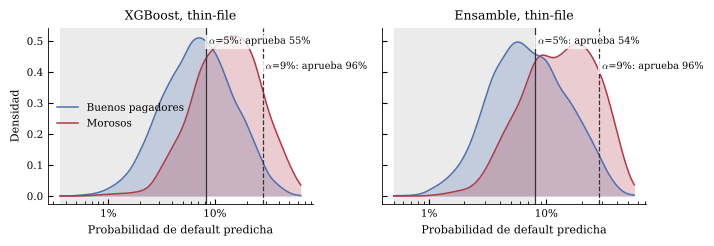

In [2]:
# Bloque 2. Figura 5 del informe: densidades del riesgo predicho dentro de thin-file, separando morosos de buenos
# pagadores, con el corte que pone Conformal Selection. Es la figura que explica el método de un vistazo: el
# conformal aprueba desde la izquierda (menor riesgo) hasta donde la proporción de morosos aprobados toca alfa, y
# cuanto más separadas estén las dos campanas, más se puede aprobar. Usamos una partición del pool (la r = 0 del 04):
# mitad para calibrar y mitad para dibujar. El corte de cada alfa es el riesgo del último aprobado.
estrato = 2 * thin.astype(int) + y
i_cal, i_test = train_test_split(np.arange(len(y)), test_size=0.5, stratify=estrato, random_state=0)
c, t = i_cal[thin[i_cal]], i_test[thin[i_test]]
ALFAS_FIG = [0.05, 0.09]

fig, ejes = plt.subplots(1, 2, figsize=(7.2, 2.5), sharey=True)
for ax, modelo in zip(ejes, ["XGBoost", "Ensamble"]):
    p = 1 / (1 + np.exp(-lg[modelo]))                    # prob. de default predicha
    mu = 1 - p                                           # prob. de buen pago (lo que usa el conformal)
    grilla = np.linspace(np.log(p[t]).min(), np.log(p[t]).max(), 400)
    for clase, color, nombre in [(0, BUENO, "Buenos pagadores"), (1, MOROSO, "Morosos")]:
        m = y[t] == clase
        dens = gaussian_kde(np.log(p[t][m]))(grilla)     # densidad en escala log del riesgo
        ax.fill_between(np.exp(grilla), dens, color=color, alpha=0.25, linewidth=0)
        ax.plot(np.exp(grilla), dens, color=color, linewidth=1.1, label=nombre)
    techo = ax.get_ylim()[1]
    for alfa, estilo in zip(ALFAS_FIG, ["-", "--"]):
        a = conformal_select(mu[c], y[c], mu[t], alfa, np.random.default_rng(0))
        corte = p[t][a].max()                            # riesgo del último aprobado
        ax.axvline(corte, color="0.2", linewidth=0.9, linestyle=estilo)
        ax.text(corte, techo * (0.95 if alfa == 0.05 else 0.80), rf" $\alpha$={alfa:.0%}: aprueba {a.mean():.0%}",
                fontsize=7, va="top", bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
        if alfa == ALFAS_FIG[0]:
            ax.axvspan(np.exp(grilla[0]), corte, color="0.85", alpha=0.5, linewidth=0, zorder=0)
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel("Probabilidad de default predicha")
    ax.set_title(f"{modelo}, thin-file")
ejes[0].set_ylabel("Densidad")
ejes[0].legend(frameon=False, loc="center left")
fig.tight_layout()
guardar(fig, "extra_densidades_conformal")
plt.show()

# En esta partición XGBoost aprueba 55% de los thin-file a alfa 5% y 96% a alfa 9%; el ensamble, 54% y 96% (el 54,4%
# del texto es el promedio de las 20 particiones). Las dos campanas están muy encimadas (AUC thin ~0.71): no hay una
# zona "limpia" de buenos pagadores para aprobar más, y por eso ningún modelo se despega. Aun así, el corte deja
# afuera a la mayor parte de los morosos.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


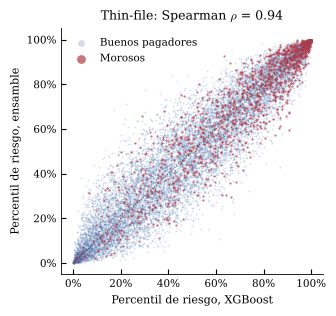

In [3]:
# Bloque 3. Figura 4 del informe: ¿XGBoost y el ensamble ordenan a los thin-file de la misma manera? Cada punto es un
# thin-file del pool, ubicado por su percentil de riesgo según cada modelo; los morosos van en rojo. Si los dos
# modelos vieran cosas distintas, la nube sería ancha; si están sobre la diagonal, ordenan casi igual. Y como
# Conformal Selection solo usa el orden, dos modelos que ordenan igual aprueban a los mismos.
r_x = rankdata(lg["XGBoost"][thin]) / thin.sum()        # percentil de riesgo según XGBoost (0 a 1)
r_e = rankdata(lg["Ensamble"][thin]) / thin.sum()       # y según el ensamble
yt = y[thin]
fig, ax = plt.subplots(figsize=(3.4, 3.2))
ax.scatter(r_x[yt == 0], r_e[yt == 0], s=1.5, color=BUENO, alpha=0.25, linewidths=0, label="Buenos pagadores")
ax.scatter(r_x[yt == 1], r_e[yt == 1], s=2.5, color=MOROSO, alpha=0.7, linewidths=0, label="Morosos")
ax.plot([0, 1], [0, 1], color="0.3", linewidth=0.7, linestyle=":")
ax.set_xlabel("Percentil de riesgo, XGBoost")
ax.set_ylabel("Percentil de riesgo, ensamble")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title(rf"Thin-file: Spearman $\rho$ = {spearmanr(r_x, r_e)[0]:.2f}")
ax.legend(frameon=False, loc="upper left", markerscale=4)
fig.tight_layout()
guardar(fig, "extra_rangos_xgb_ensamble")
plt.show()

# Spearman 0.94: los dos modelos ordenan a los thin-file casi igual, con los morosos amontonados arriba a la derecha
# en los dos. Por eso el ensamble no aprueba a más gente que XGBoost, y por eso promediarlos (08) tampoco agregó nada.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


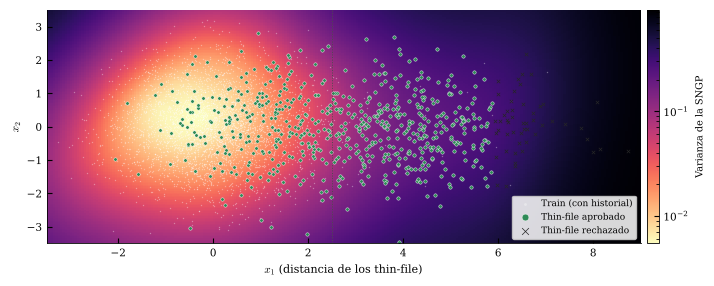

thin-file del test: 660 | aprobados: 609 | x1 mediano aprobados / rechazados: 2.77 / 6.45
morosos entre aprobados: 0.092


In [4]:
# Bloque 4. Figura 6 del informe: la simulación del 06, pero en 2 dimensiones para poder dibujarla. Clientes con
# historial alrededor del origen y thin-file corridos hacia la derecha (hasta distancia 6), con la misma "trampa" de
# riesgo lejos de los datos (desde x1 = 2.5 la mora, que venía bajando con x1, empieza a subir; es la línea punteada).
# Entrenamos una SNGP, pintamos de fondo su varianza y corremos Conformal Selection por segmento sobre los thin-file
# (alfa 10%). Lo que esperamos: la varianza crece hacia la derecha, donde no hubo datos de entrenamiento, y los
# thin-file que se rechazan son los más lejanos, donde la red sabe que no sabe.
rng = np.random.default_rng(SEED)
n_h, n_t = 6000, 1500   # 6000 clientes con historial y 1500 thin-file
X_h = rng.normal(size=(n_h, 2))
X_t = rng.normal(size=(n_t, 2))
X_t[:, 0] += rng.uniform(0, 6, size=n_t)   # thin-file corridos en x1, cada uno una distancia al azar entre 0 y 6
X = np.vstack([X_h, X_t]).astype(np.float32)
es_thin = np.r_[np.zeros(n_h, bool), np.ones(n_t, bool)]
# el mismo riesgo verdadero que en el 06: lineal cerca de los datos + la trampa desde x1 = 2.5
z = -2.2 - 0.8 * X[:, 0] + 0.5 * X[:, 1] + 2.0 * np.maximum(0, X[:, 0] - 2.5)
y2 = rng.binomial(1, 1 / (1 + np.exp(-z))).astype(np.float32)

idx_h, idx_t = rng.permutation(np.where(~es_thin)[0]), rng.permutation(np.where(es_thin)[0])
i_tr = np.r_[idx_h[:3600], idx_t[:30]]   # train: 60% de los con historial y 2% de los thin-file
i_va = np.r_[idx_h[3600:4200], idx_t[30:180]]   # validación (para el early stopping)
i_po = np.r_[idx_h[4200:], idx_t[180:]]   # pool

torch.manual_seed(SEED)
ds_tr = TensorDataset(torch.from_numpy(X[i_tr]), torch.from_numpy(y2[i_tr]))
red = SNGP(d_in=2, scale=3.0)   # con 2 variables usamos una escala de kernel más grande, como en las medias lunas
entrenar(red, DataLoader(ds_tr, batch_size=128, shuffle=True),
         DataLoader(TensorDataset(torch.from_numpy(X[i_va]), torch.from_numpy(y2[i_va])), batch_size=2048),
         lr=3e-3, max_epocas=100, paciencia=10, verbose=False)
ajustar_covarianza(red, DataLoader(ds_tr, batch_size=2048))

# grilla de 250 x 150 puntos que cubre todo el plano, para pintar la varianza de fondo
gx, gy = np.meshgrid(np.linspace(-3.5, 9, 250), np.linspace(-3.5, 3.5, 150))
G = np.c_[gx.ravel(), gy.ravel()].astype(np.float32)
_, var_g = predecir(red, torch.from_numpy(G))

# Conformal Selection por segmento sobre los thin-file del pool: mitad para calibrar (c2) y mitad para decidir (t2)
lg_po, _ = predecir(red, torch.from_numpy(X[i_po]))
mu_po = 1 - 1 / (1 + np.exp(-lg_po))   # prob. de buen pago de cada uno del pool
tp = es_thin[i_po]
c2, t2 = train_test_split(np.where(tp)[0], test_size=0.5, random_state=SEED)
apr = conformal_select(mu_po[c2], y2[i_po][c2].astype(int), mu_po[t2], 0.10, np.random.default_rng(SEED))

fig, ax = plt.subplots(figsize=(7.2, 2.9))
fondo = ax.pcolormesh(gx, gy, var_g.reshape(gx.shape), cmap="magma_r", norm=LogNorm(), shading="auto", rasterized=True)
fig.colorbar(fondo, ax=ax, fraction=0.03, pad=0.01).set_label("Varianza de la SNGP", fontsize=7)
ax.scatter(X[i_tr][:, 0], X[i_tr][:, 1], s=1, color="white", alpha=0.35, linewidths=0, label="Train (con historial)")
P = X[i_po][t2]   # los thin-file que se decidieron
ax.scatter(P[apr, 0], P[apr, 1], s=6, color="#2E8B57", linewidths=0.3, edgecolors="white", label="Thin-file aprobado")
ax.scatter(P[~apr, 0], P[~apr, 1], s=6, marker="x", color="0.15", linewidths=0.5, label="Thin-file rechazado")
ax.axvline(2.5, color="0.3", linewidth=0.7, linestyle=":")   # donde empieza la trampa
ax.set_xlim(-3.5, 9); ax.set_ylim(-3.5, 3.5)   # que el fondo llene todo el gráfico
ax.set_xlabel("$x_1$ (distancia de los thin-file)"); ax.set_ylabel("$x_2$")
ax.legend(frameon=True, framealpha=0.85, loc="lower right", fontsize=6.5, markerscale=2)
fig.tight_layout()
guardar(fig, "extra_mapa_simulacion")
plt.show()
print("thin-file del test:", len(t2), "| aprobados:", int(apr.sum()),
      "| x1 mediano aprobados / rechazados:", round(float(np.median(P[apr, 0])), 2), "/", round(float(np.median(P[~apr, 0])), 2))
print("morosos entre aprobados:", round(float(y2[i_po][t2][apr].mean()), 3))

# 660 thin-file en la mitad de prueba, 609 aprobados (92%), con 9,2% de morosos entre los aprobados (por debajo del
# 10% prometido). La mediana de x1 es 2,77 entre los aprobados y 6,45 entre los rechazados: la SNGP rechaza justo
# donde su varianza es máxima y la trampa es más fuerte, y aprueba donde hubo datos de entrenamiento. Son los números
# del párrafo de la Figura 6 en el informe.

In [5]:
# Bloque 5. El mismo mapa, pero con XGBoost: ¿qué haría el modelo estándar con estos mismos thin-file?
# Entrenamos un XGBoost con los mismos datos y la misma configuración que en el 06 (hasta 1000 árboles, early stopping
# en validación) y corremos el mismo Conformal Selection (misma calibración, mismo alfa). Miramos a cuántos aprueba y,
# sobre todo, qué pasa con los thin-file más lejanos (x1 > 5), que es donde la trampa es más fuerte.
from xgboost import XGBClassifier

xgb2 = XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=4, early_stopping_rounds=50,
                     eval_metric="logloss", random_state=SEED, n_jobs=-1)
xgb2.fit(X[i_tr], y2[i_tr], eval_set=[(X[i_va], y2[i_va])], verbose=False)
mu_x = xgb2.predict_proba(X[i_po])[:, 0]   # columna 0 = prob. de buen pago
apr_x = conformal_select(mu_x[c2], y2[i_po][c2].astype(int), mu_x[t2], 0.10, np.random.default_rng(SEED))

yt2 = y2[i_po][t2]   # quién fue moroso entre los thin-file decididos
lejos = P[:, 0] > 5   # los thin-file más lejanos
print("thin-file con x1 > 5:", int(lejos.sum()), "| mora real:", round(float(yt2[lejos].mean()), 3),
      "| mora real del resto de los thin-file:", round(float(yt2[~lejos].mean()), 3))
for nombre, mu_m, a in [("SNGP", mu_po, apr), ("XGBoost", mu_x, apr_x)]:
    riesgo = 1 - mu_m[t2]
    print(f"{nombre}: aprueba {a.mean():.1%} con {yt2[a].mean():.1%} de morosos | riesgo predicho medio x1 > 5: "
          f"{riesgo[lejos].mean():.3f} (resto {riesgo[~lejos].mean():.3f}) | aprueba al {a[lejos].mean():.0%} de los x1 > 5")

# Los dos cumplen la garantía (9,2% y 9,6% de morosos, por debajo del 10% prometido), pero con el mismo alfa la SNGP
# aprueba al 92% de los thin-file y XGBoost al 82%. Ojo con la lectura: en este ejemplo de 2 dimensiones XGBoost también
# aprende parte de la trampa con los 30 thin-file que vio en train, así que a los lejanos no les da un riesgo bajo
# (0,39, parecido al 0,40 de la SNGP). La diferencia está en cómo separa a los de cerca de los de lejos: la SNGP les da
# menos riesgo a los que están cerca de los datos (0,10 contra 0,12) y deja a los lejanos más atrás en la fila, así que
# con el mismo control de morosos puede aprobar a más gente.
# Por eso esto es solo una ilustración: el resultado general es el de la simulación de 10 variables del 06.

thin-file con x1 > 5: 114 | mora real: 0.491 | mora real del resto de los thin-file: 0.064
SNGP: aprueba 92.3% con 9.2% de morosos | riesgo predicho medio x1 > 5: 0.400 (resto 0.102) | aprueba al 55% de los x1 > 5
XGBoost: aprueba 81.8% con 9.6% de morosos | riesgo predicho medio x1 > 5: 0.387 (resto 0.120) | aprueba al 41% de los x1 > 5
